<a href="https://colab.research.google.com/github/ricardoasf/Previsao-Series-Temporais/blob/main/LimpezaDados_MissingData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Definição das bibliotecas usadas
import pandas as pd #álgebra linear
import numpy as np #processamento de dados

import matplotlib as mpl
import matplotlib.pyplot as plt #visualização de dados
import seaborn as sns #visualização de dados

############### PARAMETRIZAÇÃO PARA EXECUÇÃO #############
# 1 - para Jupyter/Outras IDEs;
# 2 - para GoogleColab
carga_dados = 2
##########################################################

if carga_dados == 1:
    #Carrega Série Temporal a partir de Planilha de Dados no formato de DataFrame
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    caminho_arquivo = filedialog.askopenfilename()
    df = pd.read_csv(caminho_arquivo)
else:
    #Carrega Dados para GoogleColab
    import io
    from google.colab import files
    uploaded = files.upload()
    #Obtém o nome do arquivo que foi feito upload
    nome_arquivo = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[nome_arquivo]))

df

Saving Dataset4.csv to Dataset4.csv


,Data,Preco
0,7/1/2009 0:00,14.25
1,7/1/2009 1:00,8.43
2,7/1/2009 2:00,1.88
3,7/1/2009 3:00,11.00
4,7/1/2009 4:00,4.21
...,...,...
1003,8/11/2009 19:00,33.12
1004,8/11/2009 20:00,38.14
1005,8/11/2009 21:00,34.04
1006,8/11/2009 22:00,20.80


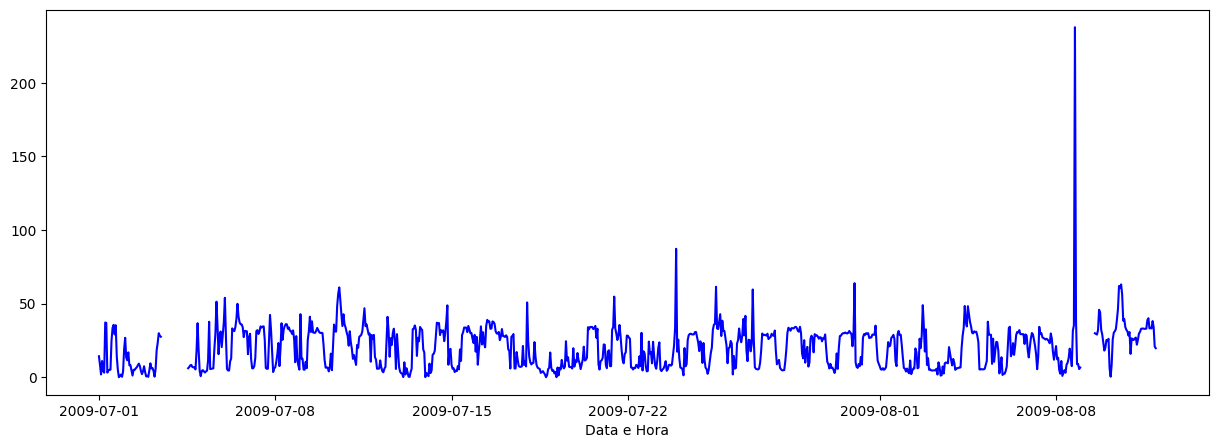

In [2]:
#Transforma a Coluna Data em DateTime
df['DateTime'] = pd.to_datetime(df['Data'])

#Torna a Coluna DateTime o índice do DataFrame
df = df.set_index(df['DateTime'])

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

In [4]:
#Detecção/Identificação das Linhas com Valores Faltantes
df_missing = pd.isnull(df['Preco'])
df[df_missing]

,Data,Preco,DateTime
DateTime,,,
2009-07-03 12:00:00,7/3/2009 12:00,NaN,2009-07-03 12:00:00
2009-07-03 13:00:00,7/3/2009 13:00,NaN,2009-07-03 13:00:00
2009-07-03 14:00:00,7/3/2009 14:00,NaN,2009-07-03 14:00:00
2009-07-03 15:00:00,7/3/2009 15:00,NaN,2009-07-03 15:00:00
2009-07-03 16:00:00,7/3/2009 16:00,NaN,2009-07-03 16:00:00
2009-07-03 17:00:00,7/3/2009 17:00,NaN,2009-07-03 17:00:00
2009-07-03 18:00:00,7/3/2009 18:00,NaN,2009-07-03 18:00:00
2009-07-03 19:00:00,7/3/2009 19:00,NaN,2009-07-03 19:00:00
2009-07-03 20:00:00,7/3/2009 20:00,NaN,2009-07-03 20:00:00


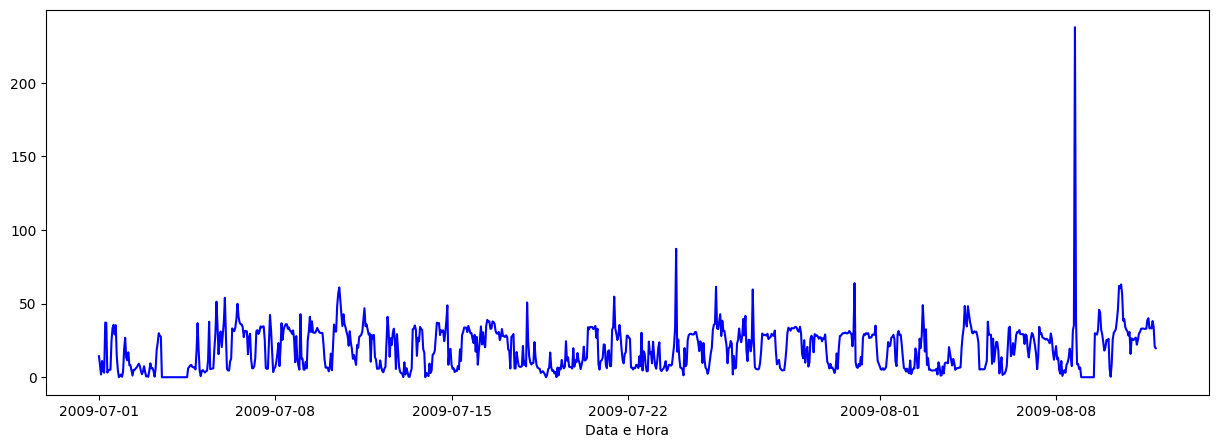

In [11]:
#Preenchendo Linhas Vazias com Zero ou Qualquer outro valor
df_fixed1 = df.fillna(0)

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed1['DateTime'], df_fixed1['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

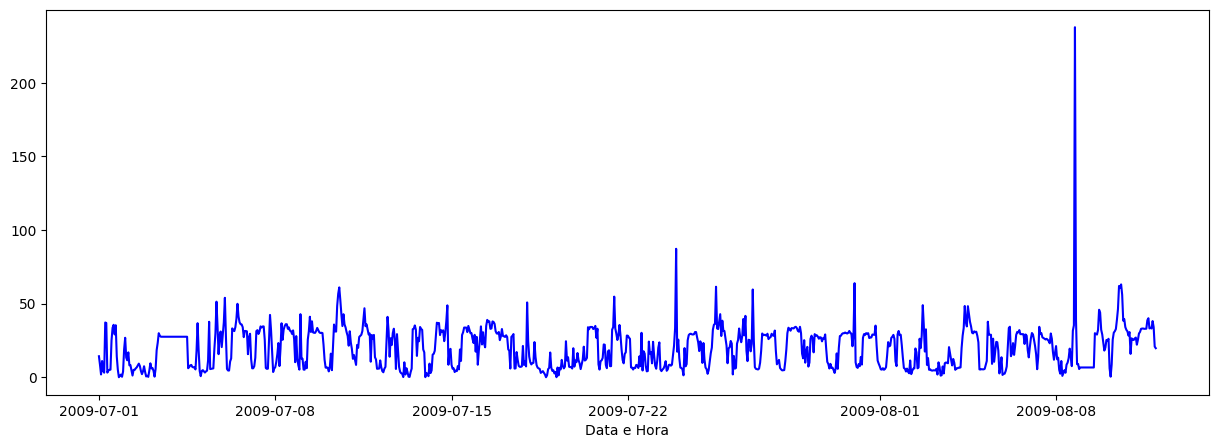

In [6]:
#Preenchendo Linhas Vazias com a Última Observação
df_fixed2 = df.ffill()

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed2['DateTime'], df_fixed2['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

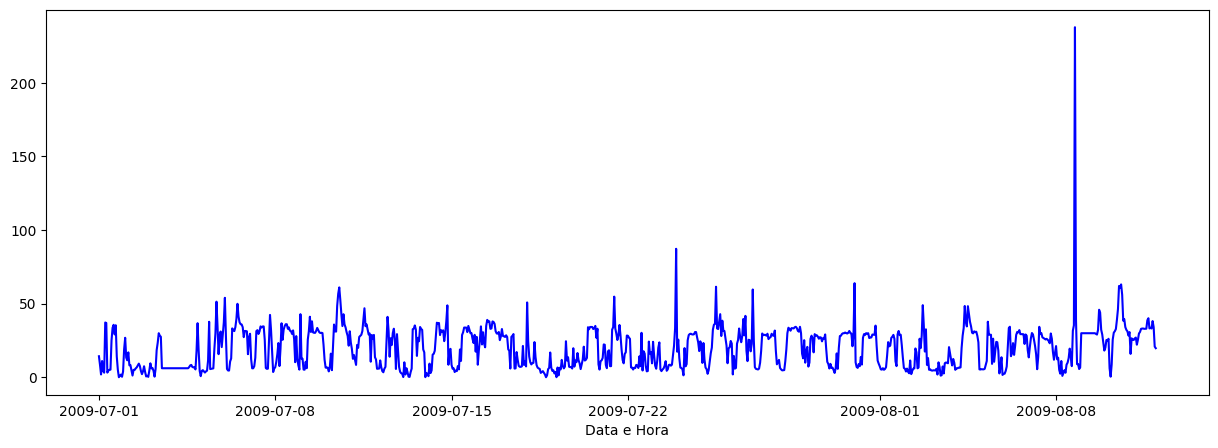

In [7]:
#Preenchendo Linhas Vazias com a Próxima Observação
df_fixed3 = df.bfill()

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed3['DateTime'], df_fixed3['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

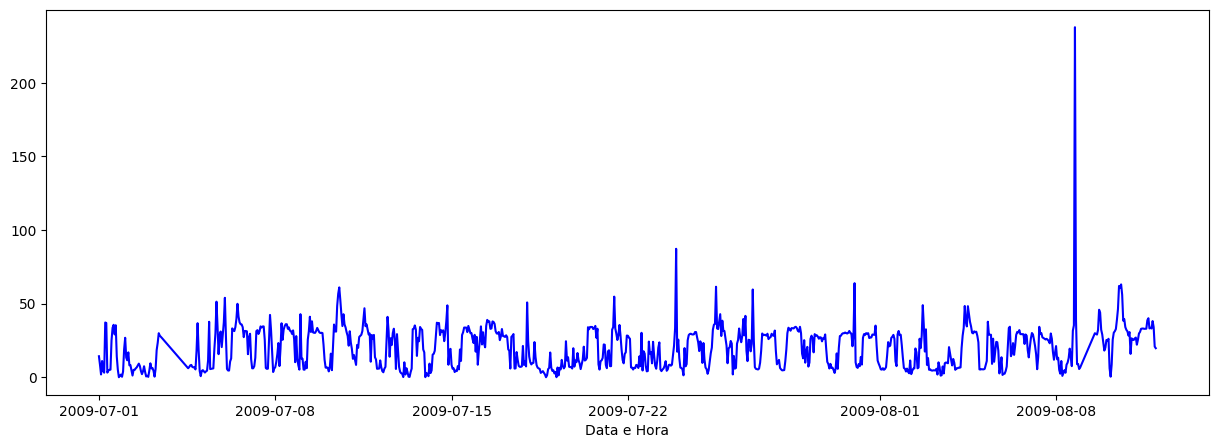

In [8]:
#Preenchendo Linhas Vazias com Interpolação
fix4 = df['Preco'].interpolate(method='linear', limit_direction ='forward')
df_fixed4 = pd.DataFrame(fix4, index=df.index, columns=['Preco'])

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed4['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

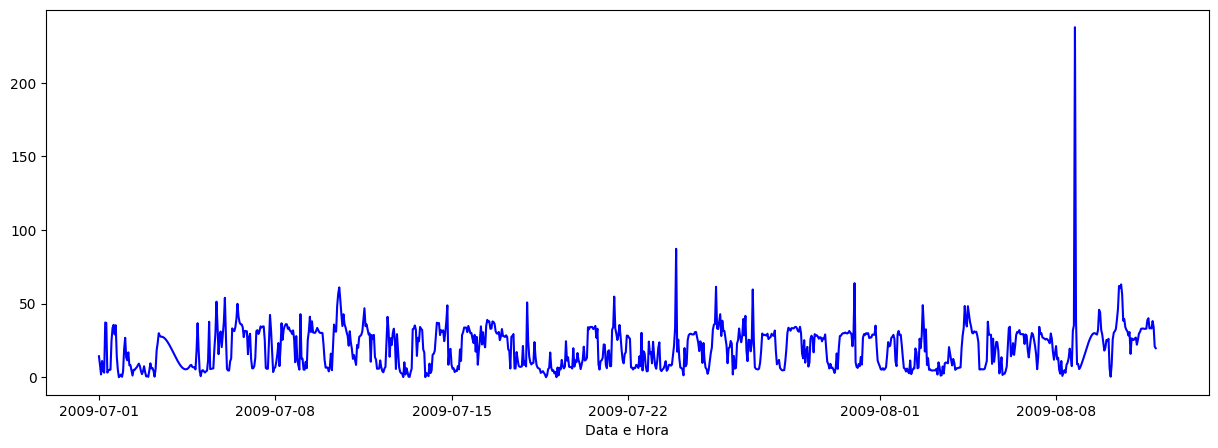

In [12]:
#Preenchendo Linhas Vazias com Interpolação
fix5 = df['Preco'].interpolate(method='polynomial', order=3)
df_fixed5 = pd.DataFrame(fix5, index=df.index, columns=['Preco'])

#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed5['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

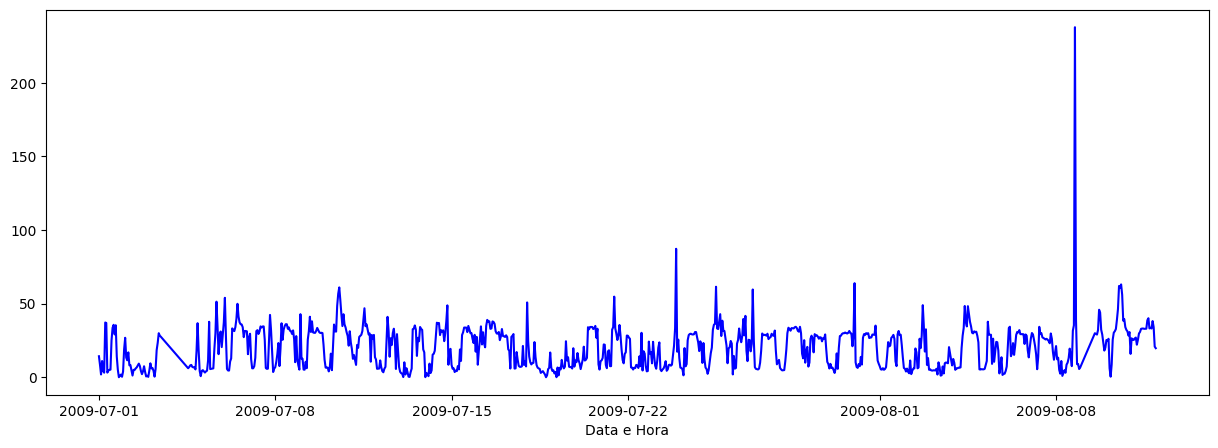

In [13]:
#Remoção de Linhas com Dados Faltantes
df_fixed6 = df.dropna()
#Análise Visual de Dados Faltantes - Missing Data
plt.figure(figsize=(15,5))
plt.plot(df_fixed6['DateTime'], df_fixed6['Preco'], 'b')
plt.xlabel('Data e Hora')
plt.show()

In [14]:
#Clona o DataFrame e Normaliza as Colunas pela primeira amostra
df_clone1 = df_fixed1[:]
df_clone1['Preco'] = df_fixed1['Preco'] / df_fixed1['Preco'].iloc[0]
df_clone2 = df_fixed2[:]
df_clone2['Preco'] = df_fixed2['Preco'] / df_fixed2['Preco'].iloc[0]
df_clone3 = df_fixed3[:]
df_clone3['Preco'] = df_fixed3['Preco'] / df_fixed3['Preco'].iloc[0]
df_clone4 = df_fixed4[:]
df_clone4['Preco'] = df_fixed4['Preco'] / df_fixed4['Preco'].iloc[0]
df_clone5 = df_fixed5[:]
df_clone5['Preco'] = df_fixed5['Preco'] / df_fixed5['Preco'].iloc[0]
df_clone6 = df_fixed6[:]
df_clone6['Preco'] = df_fixed6['Preco'] / df_fixed6['Preco'].iloc[0]

#Copia apenas as colunas de interesse do Clone para o novo DataFrame
df_norm1 = df_clone1[['Preco']]
df_norm2 = df_clone2[['Preco']]
df_norm3 = df_clone3[['Preco']]
df_norm4 = df_clone4[['Preco']]
df_norm5 = df_clone5[['Preco']]
df_norm6 = df_clone6[['Preco']]

#Clona o DataFrame normalizado para um novo
df_lagged1 = df_norm1[:]
df_lagged2 = df_norm2[:]
df_lagged3 = df_norm3[:]
df_lagged4 = df_norm4[:]
df_lagged5 = df_norm5[:]
df_lagged6 = df_norm6[:]

#Determina os atrasos (em amostras)
lags = (1, 2)

#Gera o DataFrame com as Colunas de Atraso
df_lagged1 = df_norm1.assign(**{f'{col}_t-{lag}': df_norm1[col].shift(lag) for lag in lags for col in df_norm1})
df_lagged2 = df_norm2.assign(**{f'{col}_t-{lag}': df_norm2[col].shift(lag) for lag in lags for col in df_norm2})
df_lagged3 = df_norm3.assign(**{f'{col}_t-{lag}': df_norm3[col].shift(lag) for lag in lags for col in df_norm3})
df_lagged4 = df_norm4.assign(**{f'{col}_t-{lag}': df_norm4[col].shift(lag) for lag in lags for col in df_norm4})
df_lagged5 = df_norm5.assign(**{f'{col}_t-{lag}': df_norm5[col].shift(lag) for lag in lags for col in df_norm5})
df_lagged6 = df_norm6.assign(**{f'{col}_t-{lag}': df_norm6[col].shift(lag) for lag in lags for col in df_norm6})

#Exclui valor NaN resultantes do Lag
df_proc1 = df_lagged1.dropna()
df_proc2 = df_lagged2.dropna()
df_proc3 = df_lagged3.dropna()
df_proc4 = df_lagged4.dropna()
df_proc5 = df_lagged5.dropna()
df_proc6 = df_lagged6.dropna()

In [15]:
#Define as colunas que serão variáveis de entrada - explicativas
features = df_proc1.columns[[1]]
features

Index(['Preco_t-1'], dtype='object')

In [16]:
#Define a coluna que será variável de saída - interesse
target = df_proc1.columns[[0]]
target

Index(['Preco'], dtype='object')

In [17]:
#Separação de Dados para Ajuste e Validação dos Modelos
df_t_ajuste1 = df_proc1['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao1 = df_proc1['2009-08-01 00:00:00':].index.values
df_dados_ajuste1 = df_proc1['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao1 = df_proc1['2009-08-01 00:00:00':]

df_t_ajuste2 = df_proc2['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao2 = df_proc2['2009-08-01 00:00:00':].index.values
df_dados_ajuste2 = df_proc2['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao2 = df_proc2['2009-08-01 00:00:00':]

df_t_ajuste3 = df_proc3['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao3 = df_proc3['2009-08-01 00:00:00':].index.values
df_dados_ajuste3 = df_proc3['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao3 = df_proc3['2009-08-01 00:00:00':]

df_t_ajuste4 = df_proc4['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao4 = df_proc4['2009-08-01 00:00:00':].index.values
df_dados_ajuste4 = df_proc4['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao4 = df_proc4['2009-08-01 00:00:00':]

df_t_ajuste5 = df_proc5['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao5 = df_proc5['2009-08-01 00:00:00':].index.values
df_dados_ajuste5 = df_proc5['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao5 = df_proc5['2009-08-01 00:00:00':]

df_t_ajuste6 = df_proc6['2009-07-01 00:00:00':'2009-07-31 23:00:00'].index.values
df_t_validacao6 = df_proc6['2009-08-01 00:00:00':].index.values
df_dados_ajuste6 = df_proc6['2009-07-01 00:00:00':'2009-07-31 23:00:00']
df_dados_validacao6 = df_proc6['2009-08-01 00:00:00':]

X_ajuste1 = df_dados_ajuste1[features].values
Y_ajuste1 = df_dados_ajuste1[target].values
X_validacao1 = df_dados_validacao1[features].values
Y_validacao1 = df_dados_validacao1[target].values

X_ajuste2 = df_dados_ajuste2[features].values
Y_ajuste2 = df_dados_ajuste2[target].values
X_validacao2 = df_dados_validacao2[features].values
Y_validacao2 = df_dados_validacao2[target].values

X_ajuste3 = df_dados_ajuste3[features].values
Y_ajuste3 = df_dados_ajuste3[target].values
X_validacao3 = df_dados_validacao3[features].values
Y_validacao3 = df_dados_validacao3[target].values

X_ajuste4 = df_dados_ajuste4[features].values
Y_ajuste4 = df_dados_ajuste4[target].values
X_validacao4 = df_dados_validacao4[features].values
Y_validacao4 = df_dados_validacao4[target].values

X_ajuste5 = df_dados_ajuste5[features].values
Y_ajuste5 = df_dados_ajuste5[target].values
X_validacao5 = df_dados_validacao5[features].values
Y_validacao5 = df_dados_validacao5[target].values

X_ajuste6 = df_dados_ajuste6[features].values
Y_ajuste6 = df_dados_ajuste6[target].values
X_validacao6 = df_dados_validacao6[features].values
Y_validacao6 = df_dados_validacao6[target].values

In [18]:
# Parametrização de Modelo de Regressão Linear
from sklearn.linear_model import LinearRegression

modelo_RL1 = LinearRegression().fit(X_ajuste1, Y_ajuste1)
modelo_RL2 = LinearRegression().fit(X_ajuste2, Y_ajuste2)
modelo_RL3 = LinearRegression().fit(X_ajuste3, Y_ajuste3)
modelo_RL4 = LinearRegression().fit(X_ajuste4, Y_ajuste4)
modelo_RL5 = LinearRegression().fit(X_ajuste5, Y_ajuste5)
modelo_RL6 = LinearRegression().fit(X_ajuste6, Y_ajuste6)

In [19]:
df_previsto_RL1 = modelo_RL1.predict(X_validacao1)
df_previsto_RL1_denorm = df_previsto_RL1 * df_fixed1['Preco'].iloc[0]

df_previsto_RL2 = modelo_RL2.predict(X_validacao2)
df_previsto_RL2_denorm = df_previsto_RL2 * df_fixed2['Preco'].iloc[0]

df_previsto_RL3 = modelo_RL3.predict(X_validacao3)
df_previsto_RL3_denorm = df_previsto_RL3 * df_fixed3['Preco'].iloc[0]

df_previsto_RL4 = modelo_RL4.predict(X_validacao4)
df_previsto_RL4_denorm = df_previsto_RL4 * df_fixed4['Preco'].iloc[0]

df_previsto_RL5 = modelo_RL5.predict(X_validacao5)
df_previsto_RL5_denorm = df_previsto_RL5 * df_fixed5['Preco'].iloc[0]

df_previsto_RL6 = modelo_RL6.predict(X_validacao6)
df_previsto_RL6_denorm = df_previsto_RL6 * df_fixed6['Preco'].iloc[0]

In [20]:
r_sq1 = modelo_RL1.score(X_validacao1, Y_validacao1)
print(f"Modelo 1 - R2: {r_sq1}")

r_sq2 = modelo_RL2.score(X_validacao2, Y_validacao2)
print(f"Modelo 2 - R2: {r_sq2}")

r_sq3 = modelo_RL3.score(X_validacao3, Y_validacao3)
print(f"Modelo 3 - R2: {r_sq3}")

r_sq4 = modelo_RL4.score(X_validacao4, Y_validacao4)
print(f"Modelo 4 - R2: {r_sq4}")

r_sq5 = modelo_RL5.score(X_validacao5, Y_validacao5)
print(f"Modelo 5 - R2: {r_sq5}")

r_sq6 = modelo_RL6.score(X_validacao6, Y_validacao6)
print(f"Modelo 6 - R2: {r_sq6}")

Modelo 1 - R2: 0.19160960584327857
Modelo 2 - R2: 0.17927734852143318
Modelo 3 - R2: 0.15975392240370656
Modelo 4 - R2: 0.1653606687355541
Modelo 5 - R2: 0.16457483523203098
Modelo 6 - R2: 0.15827989870491366


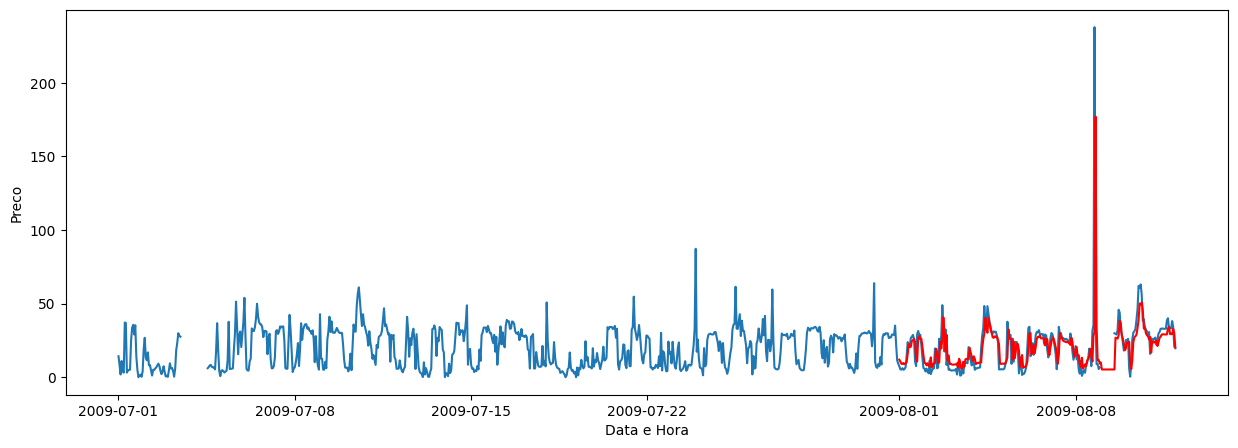

In [23]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RL1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()

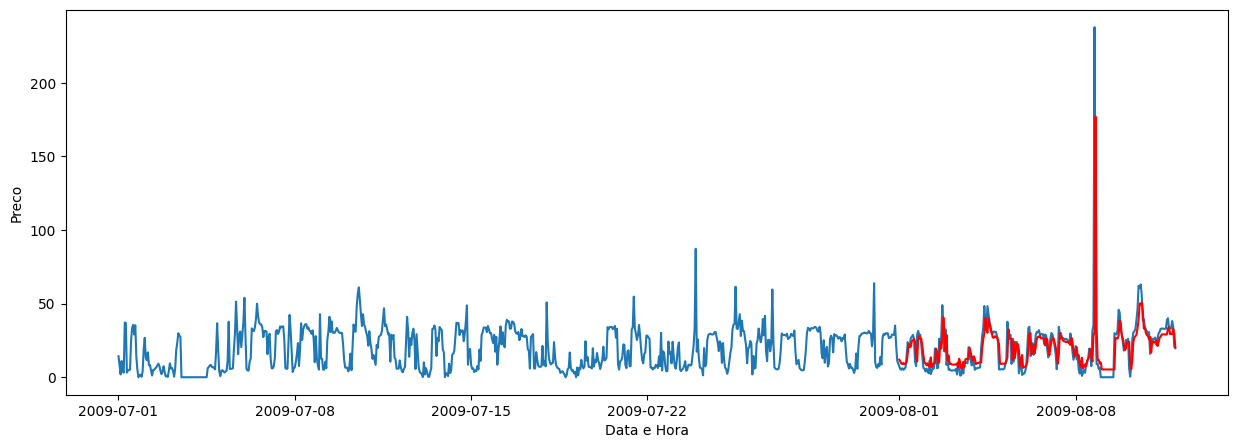

In [24]:
plt.figure(figsize=(15,5))
plt.plot(df_fixed1['DateTime'], df_fixed1['Preco'])
plt.plot(df_dados_validacao1.index, df_previsto_RL1_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()

In [25]:
# Parametrização de Modelo de Regressão Polinomial
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

#Polinômio de grau = 1, então Polinomial = Linear
modelo_RP1 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste1, Y_ajuste1)
modelo_RP2 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste2, Y_ajuste2)
modelo_RP3 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste3, Y_ajuste3)
modelo_RP4 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste4, Y_ajuste4)
modelo_RP5 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste5, Y_ajuste5)
modelo_RP6 = Pipeline([('poly', PolynomialFeatures(degree=2)), ('linear', LinearRegression(fit_intercept=True))]).fit(X_ajuste6, Y_ajuste6)

In [26]:
df_previsto_RP1 = modelo_RP1.predict(X_validacao1)
df_previsto_RP1_denorm = df_previsto_RP1 * df_fixed1['Preco'].iloc[0]

df_previsto_RP2 = modelo_RP2.predict(X_validacao2)
df_previsto_RP2_denorm = df_previsto_RP2 * df_fixed2['Preco'].iloc[0]

df_previsto_RP3 = modelo_RP3.predict(X_validacao3)
df_previsto_RP3_denorm = df_previsto_RP3 * df_fixed3['Preco'].iloc[0]

df_previsto_RP4 = modelo_RP4.predict(X_validacao4)
df_previsto_RP4_denorm = df_previsto_RP4 * df_fixed4['Preco'].iloc[0]

df_previsto_RP5 = modelo_RP5.predict(X_validacao5)
df_previsto_RP5_denorm = df_previsto_RP5 * df_fixed5['Preco'].iloc[0]

df_previsto_RP6 = modelo_RP6.predict(X_validacao6)
df_previsto_RP6_denorm = df_previsto_RP6 * df_fixed6['Preco'].iloc[0]

In [27]:
r_sq1 = modelo_RP1.score(X_validacao1, Y_validacao1)
print(f"Modelo 1 - R2: {r_sq1}")

r_sq2 = modelo_RP2.score(X_validacao2, Y_validacao2)
print(f"Modelo 2 - R2: {r_sq2}")

r_sq3 = modelo_RP3.score(X_validacao3, Y_validacao3)
print(f"Modelo 3 - R2: {r_sq3}")

r_sq4 = modelo_RP4.score(X_validacao4, Y_validacao4)
print(f"Modelo 4 - R2: {r_sq4}")

r_sq5 = modelo_RP5.score(X_validacao5, Y_validacao5)
print(f"Modelo 5 - R2: {r_sq5}")

r_sq6 = modelo_RP6.score(X_validacao6, Y_validacao6)
print(f"Modelo 6 - R2: {r_sq6}")

Modelo 1 - R2: -0.927824353040605
Modelo 2 - R2: -0.8957566080142254
Modelo 3 - R2: -0.9613790979069956
Modelo 4 - R2: -0.8865517162992145
Modelo 5 - R2: -0.9123752642535385
Modelo 6 - R2: -0.9302106089390014


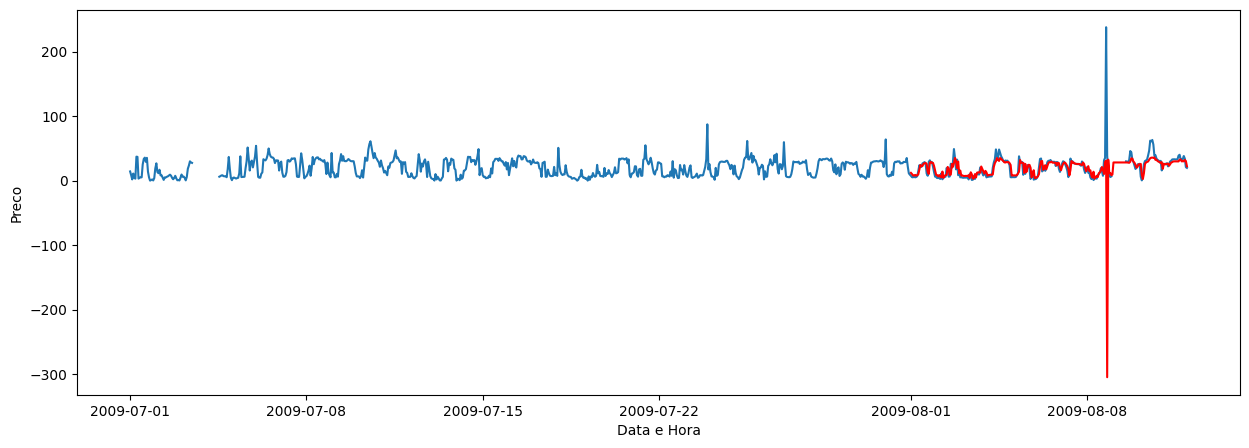

In [28]:
plt.figure(figsize=(15,5))
plt.plot(df['DateTime'], df['Preco'])
plt.plot(df_dados_validacao3.index, df_previsto_RP3_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()

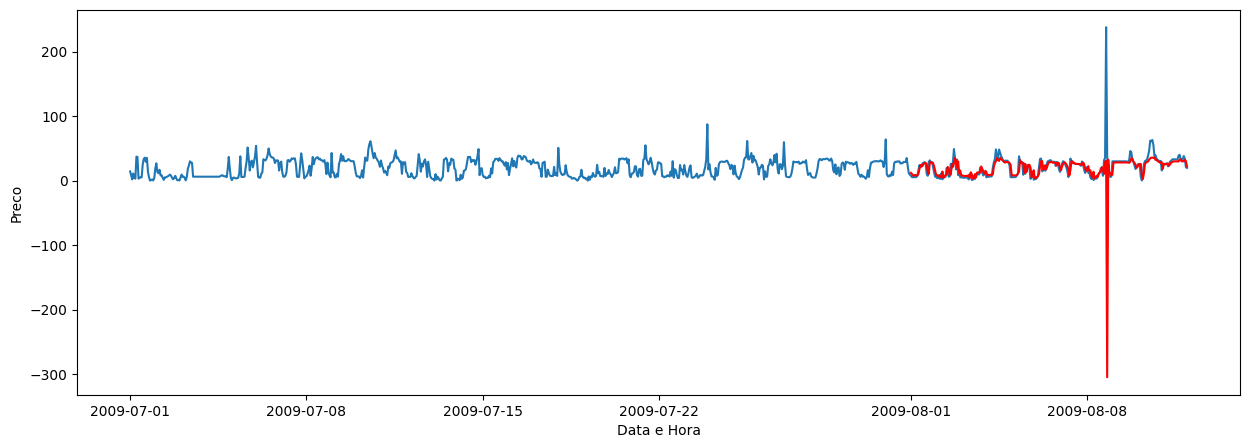

In [29]:
plt.figure(figsize=(15,5))
plt.plot(df_fixed3['DateTime'], df_fixed3['Preco'])
plt.plot(df_dados_validacao3.index, df_previsto_RP3_denorm, 'r')
plt.ylabel('Preco')
plt.xlabel('Data e Hora')
plt.show()